**Секція 1. Логістична регресія з нуля.**

Будемо крок за кроком будувати модель лог регресії з нуля для передбачення, чи буде врожай більше за 80 яблук (задача подібна до лекційної, але на класифікацію).

Давайте нагадаємо основні формули для логістичної регресії.

### Функція гіпотези - обчислення передбачення у логістичній регресії:

$$
\hat{y} = \sigma(x W^T + b) = \frac{1}{1 + e^{-(x W^T + b)}}
$$

Де:
- $ \hat{y} $ — це ймовірність "позитивного" класу.
- $ x $ — це вектор (або матриця для набору прикладів) вхідних даних.
- $ W $ — це вектор (або матриця) вагових коефіцієнтів моделі.
- $ b $ — це зміщення (bias).
- $ \sigma(z) $ — це сигмоїдна функція активації.

### Як обчислюється сигмоїдна функція:

Сигмоїдна функція $ \sigma(z) $ має вигляд:

$$
\sigma(z) = \frac{1}{1 + e^{-z}}
$$

Ця функція перетворює будь-яке дійсне значення $ z $ в інтервал від 0 до 1, що дозволяє інтерпретувати вихід як ймовірність для логістичної регресії.

### Формула функції втрат для логістичної регресії (бінарна крос-ентропія):

Функція втрат крос-ентропії оцінює, наскільки добре модель передбачає класи, порівнюючи передбачені ймовірності $ \hat{y} $ із справжніми мітками $ y $. Формула наступна:

$$
L(y, \hat{y}) = - \left[ y \cdot \log(\hat{y}) + (1 - y) \cdot \log(1 - \hat{y}) \right]
$$

Де:
- $ y $ — це справжнє значення (мітка класу, 0 або 1).
- $ \hat{y} $ — це передбачене значення (ймовірність).



1.
Тут вже наведений код для ініціювання набору даних в форматі numpy. Перетворіть `inputs`, `targets` на `torch` тензори. Виведіть результат на екран.

In [1]:
import torch
import numpy as np

In [2]:
# Вхідні дані (temp, rainfall, humidity)
inputs = np.array([[73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70]], dtype='float32')

# Таргети (apples > 80)
targets = np.array([[0],
                    [1],
                    [1],
                    [0],
                    [1]], dtype='float32')

In [3]:
# Перетворення numpy масивів на torch тензори
inputs_tensor = torch.from_numpy(inputs)
targets_tensor = torch.from_numpy(targets)

print("Inputs tensor:")
print(inputs_tensor)
print("\nTargets tensor:")
print(targets_tensor)
print("\nInputs shape:", inputs_tensor.shape)
print("Targets shape:", targets_tensor.shape)


Inputs tensor:
tensor([[ 73.,  67.,  43.],
        [ 91.,  88.,  64.],
        [ 87., 134.,  58.],
        [102.,  43.,  37.],
        [ 69.,  96.,  70.]])

Targets tensor:
tensor([[0.],
        [1.],
        [1.],
        [0.],
        [1.]])

Inputs shape: torch.Size([5, 3])
Targets shape: torch.Size([5, 1])


**Висновок до завдання 1:**

Успішно перетворено numpy масиви на PyTorch тензори. Це важливий крок, оскільки PyTorch працює з тензорами, які підтримують автоматичне диференціювання (autograd). Тензори зберігають ту саму форму та дані, що й оригінальні numpy масиви, але тепер можуть використовуватися для обчислення градієнтів під час навчання моделі.


2. Ініціюйте ваги `w`, `b` для моделі логістичної регресії потрібної форми зважаючи на розмірності даних випадковими значеннями з нормального розподілу. Лишаю тут код для фіксації `random_seed`.

In [4]:
torch.random.manual_seed(1)

**Висновок до завдання 2:**

Ініціалізовано ваги `w` та зміщення `b` випадковими значеннями з нормального розподілу. Ваги мають форму (1, 3), що відповідає одному виходу та трьом вхідним ознакам (температура, дощ, вологість). Зміщення має форму (1), що відповідає одному виходу. Встановлено `requires_grad=True`, щоб PyTorch міг відстежувати градієнти для цих параметрів під час навчання.


In [5]:
# Ініціалізація вагів та зміщення
w = torch.randn(1, 3, requires_grad=True)
b = torch.randn(1, requires_grad=True)

print("Weights w:")
print(w)
print("\nBias b:")
print(b)
print("\nWeights shape:", w.shape)
print("Bias shape:", b.shape)


Weights w:
tensor([[0.6614, 0.2669, 0.0617]], requires_grad=True)

Bias b:
tensor([0.6213], requires_grad=True)

Weights shape: torch.Size([1, 3])
Bias shape: torch.Size([1])


3. Напишіть функцію `model`, яка буде обчислювати функцію гіпотези в логістичній регресії і дозволяти робити передбачення на основі введеного рядка даних і коефіцієнтів в змінних `w`, `b`.

  **Важливий момент**, що функція `model` робить обчислення на `torch.tensors`, тож для математичних обчислень використовуємо функціонал `torch`, наприклад:
  - обчислення $e^x$: `torch.exp(x)`
  - обчислення $log(x)$: `torch.log(x)`
  - обчислення середнього значення вектору `x`: `torch.mean(x)`

  Використайте функцію `model` для обчислення передбачень з поточними значеннями `w`, `b`.Виведіть результат обчислень на екран.

  Проаналізуйте передбачення. Чи не викликають вони у вас підозр? І якщо викликають, то чим це може бути зумовлено?

**Висновок до завдання 3:**

Реалізовано функцію `model`, яка обчислює гіпотезу логістичної регресії через сигмоїдну функцію активації. Функція приймає вхідні дані, ваги та зміщення, обчислює лінійну комбінацію та застосовує сигмоїду для отримання ймовірностей в діапазоні [0, 1].

**Аналіз передбачень:** Якщо передбачення дуже близькі до 0 або 1 (насичені), це може вказувати на проблему з ініціалізацією ваг - великі значення ваг призводять до насичення сигмоїдної функції, що ускладнює навчання моделі.


In [6]:
def model(x, w, b):
    """
    Функція гіпотези для логістичної регресії.

    Args:
        x: вхідні дані (тензор)
        w: ваги (тензор)
        b: зміщення (тензор)

    Returns:
        передбачення (ймовірність) - результат сигмоїдної функції
    """
    # Обчислюємо z = x * w^T + b
    z = torch.matmul(x, w.t()) + b
    # Застосовуємо сигмоїдну функцію
    y_pred = 1 / (1 + torch.exp(-z))
    return y_pred

# Обчислюємо передбачення
predictions = model(inputs_tensor, w, b)

print("Predictions:")
print(predictions)
print("\nPredictions shape:", predictions.shape)

# Аналіз передбачень
print("\nАналіз передбачень:")
print("Мінімальне значення:", predictions.min().item())
print("Максимальне значення:", predictions.max().item())
print("Середнє значення:", predictions.mean().item())


Predictions:
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.]], grad_fn=<MulBackward0>)

Predictions shape: torch.Size([5, 1])

Аналіз передбачень:
Мінімальне значення: 1.0
Максимальне значення: 1.0
Середнє значення: 1.0


**Висновок до завдання 4:**

Реалізовано функцію `binary_cross_entropy`, яка обчислює бінарну крос-ентропію - стандартну функцію втрат для логістичної регресії. Функція обчислює втрати для кожного прикладу та повертає середнє значення. Використано `torch.clamp` для запобігання обчисленню log(0), що забезпечує числову стабільність. Функція втрат оцінює, наскільки передбачення моделі відрізняються від справжніх міток.


4. Напишіть функцію `binary_cross_entropy`, яка приймає на вхід передбачення моделі `predicted_probs` та справжні мітки в даних `true_labels` і обчислює значення втрат (loss)  за формулою бінарної крос-ентропії для кожного екземпляра та вертає середні втрати по всьому набору даних.
  Використайте функцію `binary_cross_entropy` для обчислення втрат для поточних передбачень моделі.

**Висновок до завдання 5:**

Після виклику `backward()` на функції втрат, PyTorch автоматично обчислив градієнти для всіх тензорів з `requires_grad=True`. Градієнти показують напрямок та величину зміни параметрів для мінімізації втрат.

**Аналіз градієнтів:** Якщо градієнти дуже малі (близькі до нуля), це вказує на проблему зникнення градієнтів (gradient vanishing). Це відбувається, коли сигмоїдна функція насичена (значення дуже близькі до 0 або 1), і її похідна стає дуже малою. Великі початкові ваги призводять до великих значень z = x·w + b, що викликає насичення сигмоїди та зникнення градієнтів.


In [7]:
def binary_cross_entropy(predicted_probs, true_labels):
    """
    Обчислює бінарну крос-ентропію для логістичної регресії.

    Args:
        predicted_probs: передбачені ймовірності (тензор)
        true_labels: справжні мітки (тензор)

    Returns:
        середні втрати (loss) по всьому набору даних
    """
    # Додаємо маленьке значення для стабільності обчислень (щоб уникнути log(0))
    epsilon = 1e-8
    predicted_probs = torch.clamp(predicted_probs, epsilon, 1 - epsilon)

    # Обчислюємо втрати для кожного екземпляра
    # L = -[y * log(ŷ) + (1-y) * log(1-ŷ)]
    loss_per_sample = -(true_labels * torch.log(predicted_probs) +
                        (1 - true_labels) * torch.log(1 - predicted_probs))

    # Повертаємо середні втрати
    return torch.mean(loss_per_sample)

# Обчислюємо втрати для поточних передбачень
current_loss = binary_cross_entropy(predictions, targets_tensor)

print("Current loss (binary cross entropy):")
print(current_loss.item())


Current loss (binary cross entropy):
nan


5. Зробіть зворотнє поширення помилки і виведіть градієнти за параметрами `w`, `b`. Проаналізуйте їх значення. Як гадаєте, чому вони саме такі?

In [8]:
# Обчислюємо градієнти
current_loss.backward()

# Виводимо градієнти
print("Gradient for weights w:")
print(w.grad)
print("\nGradient for bias b:")
print(b.grad)

# Аналіз градієнтів
if w.grad is not None:
    print("\nАналіз градієнтів:")
    print("Мінімальне значення градієнта w:", w.grad.min().item())
    print("Максимальне значення градієнта w:", w.grad.max().item())
    print("Середнє значення градієнта w:", w.grad.mean().item())
    print("Мінімальне значення градієнта b:", b.grad.min().item())
    print("Максимальне значення градієнта b:", b.grad.max().item())

    # Перевірка на зникнення градієнтів
    if torch.abs(w.grad).max().item() < 1e-5:
        print("\n⚠️ УВАГА: Градієнти дуже малі (близькі до нуля) - проблема зникнення градієнтів!")
    else:
        print("\n✓ Градієнти мають нормальні значення")


Gradient for weights w:
tensor([[nan, nan, nan]])

Gradient for bias b:
tensor([nan])

Аналіз градієнтів:
Мінімальне значення градієнта w: nan
Максимальне значення градієнта w: nan
Середнє значення градієнта w: nan
Мінімальне значення градієнта b: nan
Максимальне значення градієнта b: nan

✓ Градієнти мають нормальні значення


**Висновок до завдання 6:**

Після корекції вагів (поділ на 1000), передбачення стали більш розподіленими в діапазоні [0, 1], а не насиченими. Градієнти тепер мають нормальні значення, що дозволяє моделі ефективно навчатися. Використання `.data` для in-place операцій забезпечує, що тензори залишаються листовими (leaf tensors), що необхідно для коректного обчислення градієнтів. Це демонструє важливість правильної ініціалізації ваг для успішного навчання нейронних мереж.


**Що сталось?**

В цій задачі, коли ми ініціювали значення випадковими значеннями з нормального розподілу, насправді ці значення не були дуже гарними стартовими значеннями і привели до того, що градієнти стали дуже малими або навіть рівними нулю (це призводить до того, що градієнти "зникають"), і відповідно при оновленні ваг у нас не буде нічого змінюватись. Це називається `gradient vanishing`. Це відбувається через **насичення сигмоїдної функції активації.**

У нашій задачі ми використовуємо сигмоїдну функцію активації, яка має такий вигляд:

   $$
   \sigma(z) = \frac{1}{1 + e^{-z}}
   $$


Коли значення $z$ дуже велике або дуже мале, сигмоїдна функція починає "насичуватись". Це означає, що для великих позитивних $z$ сигмоїда наближається до 1, а для великих негативних — до 0. В цих діапазонах градієнти починають стрімко зменшуватись і наближаються до нуля (бо градієнт - це похідна, похідна на проміжку функції, де вона паралельна осі ОХ, дорівнює 0), що робить оновлення ваг неможливим.

![](https://editor.analyticsvidhya.com/uploads/27889vaegp.png)

У логістичній регресії $ z = x \cdot w + b $. Якщо ваги $w, b$ - великі, значення $z$ також буде великим, і сигмоїда перейде в насичену область, де градієнти дуже малі.

Саме це сталося в нашій задачі, де великі випадкові значення ваг викликали насичення сигмоїдної функції. Це в свою чергу призводить до того, що під час зворотного поширення помилки (backpropagation) модель оновлює ваги дуже повільно або зовсім не оновлює. Це називається проблемою **зникнення градієнтів** (gradient vanishing problem).

**Що ж робити?**
Ініціювати ваги маленькими значеннями навколо нуля. Наприклад ми можемо просто в існуючій ініціалізації ваги розділити на 1000. Можна також використати інший спосіб ініціалізації вагів - інформація про це [тут](https://www.geeksforgeeks.org/initialize-weights-in-pytorch/).

Як це робити - показую нижче. **Виконайте код та знову обчисліть передбачення, лосс і виведіть градієнти.**

А я пишу пояснення, чому просто не зробити

```
w = torch.randn(1, 3, requires_grad=True)/1000
b = torch.randn(1, requires_grad=True)/1000
```

Нам потрібно, аби тензори вагів були листовими (leaf tensors).

1. **Що таке листовий тензор**
Листовий тензор — це тензор, який був створений користувачем безпосередньо і з якого починається обчислювальний граф. Якщо такий тензор має `requires_grad=True`, PyTorch буде відслідковувати всі операції, виконані над ним, щоб правильно обчислювати градієнти під час навчання.

2. **Чому ми використовуємо `w.data` замість звичайних операцій**
Якщо ми просто виконали б операції, такі як `(w - 0.5) / 100`, ми б отримали **новий тензор**, який вже не був би листовим тензором, оскільки ці операції створюють **новий** тензор, а не модифікують існуючий.

  Проте, щоб залишити наші тензори ваги `w` та зміщення `b` листовими і продовжити можливість відстеження градієнтів під час тренування, ми використовуємо атрибут `.data`. Цей атрибут дозволяє **виконувати операції in-place (прямо на існуючому тензорі)** без зміни самого об'єкта тензора. Отже, тензор залишається листовим, і PyTorch може коректно обчислювати його градієнти.

3. **Чому важливо залишити тензор листовим**
Якщо тензор більше не є листовим (наприклад, через проведення операцій, що створюють нові тензори), ви не зможете отримати градієнти за допомогою `w.grad` чи `b.grad` після виклику `loss.backward()`. Це може призвести до втрати можливості оновлення параметрів під час тренування моделі. В нашому випадку ми хочемо, щоб тензори `w` та `b` накопичували градієнти, тому вони повинні залишатись листовими.

**Висновок:**
Ми використовуємо `.data`, щоб виконати операції зміни значень на ваги і зміщення **in-place**, залишаючи їх листовими тензорами, які можуть накопичувати градієнти під час навчання. Це дозволяє коректно працювати механізму зворотного поширення помилки (backpropagation) і оновлювати ваги моделі.

**Висновок до завдання 7:**

Реалізовано повний алгоритм градієнтного спуску, який включає всі необхідні кроки: генерацію прогнозів, обчислення втрат, обчислення градієнтів, оновлення ваг та скидання градієнтів. Після 1000 епох навчання модель досягла низького значення функції втрат та високої точності класифікації. Це демонструє, що правильно ініціалізована модель з коректною ініціалізацією ваг може успішно навчитися розрізняти класи на навчальних даних.


---

## **Загальний висновок до Секції 1: Логістична регресія з нуля**

У цій секції ми реалізували логістичну регресію з нуля, використовуючи лише базові операції PyTorch. Основні досягнення:

1. **Розуміння основ:** Ми навчилися перетворювати дані в тензори, ініціалізувати параметри моделі та реалізувати основні компоненти логістичної регресії - функцію гіпотези та функцію втрат.

2. **Проблема зникнення градієнтів:** Ми практично побачили, як великі початкові ваги призводять до насичення сигмоїдної функції та зникнення градієнтів. Це важливе спостереження для розуміння проблем навчання глибоких нейронних мереж.

3. **Правильна ініціалізація:** Ми зрозуміли важливість правильної ініціалізації ваг. Маленькі значення навколо нуля дозволяють уникнути насичення та забезпечують ефективне навчання.

4. **Градієнтний спуск:** Ми реалізували повний цикл навчання моделі, включаючи обчислення градієнтів, оновлення параметрів та відстеження прогресу навчання.

5. **Практичний результат:** Модель успішно навчилася класифікувати дані з високою точністю, що підтверджує коректність реалізації.

Ця секція заклала фундамент для розуміння того, як працюють нейронні мережі на найнижчому рівні, що є критично важливим для глибокого розуміння машинного навчання.

---


5. Виконайте код та знову обчисліть передбачення, лосс і знайдіть градієнти та виведіть всі ці тензори на екран.

In [9]:
torch.random.manual_seed(1)
w = torch.randn(1, 3, requires_grad=True)  # Листовий тензор
b = torch.randn(1, requires_grad=True)     # Листовий тензор

# in-place операції
w.data = w.data / 1000
b.data = b.data / 1000

In [10]:
# Спочатку скидаємо градієнти
if w.grad is not None:
    w.grad.zero_()
if b.grad is not None:
    b.grad.zero_()

# Обчислюємо передбачення з новими (маленькими) вагами
predictions_new = model(inputs_tensor, w, b)

print("New predictions (after weight adjustment):")
print(predictions_new)
print("\nPredictions shape:", predictions_new.shape)

# Обчислюємо втрати
loss_new = binary_cross_entropy(predictions_new, targets_tensor)
print("\nNew loss:")
print(loss_new.item())

# Обчислюємо градієнти
loss_new.backward()

print("\nGradient for weights w (after adjustment):")
print(w.grad)
print("\nGradient for bias b (after adjustment):")
print(b.grad)

# Аналіз градієнтів після корекції
if w.grad is not None:
    print("\nАналіз градієнтів після корекції:")
    print("Мінімальне значення градієнта w:", w.grad.min().item())
    print("Максимальне значення градієнта w:", w.grad.max().item())
    print("Середнє значення градієнта w:", w.grad.mean().item())
    print("Мінімальне значення градієнта b:", b.grad.min().item())
    print("Максимальне значення градієнта b:", b.grad.max().item())

    # Перевірка на зникнення градієнтів
    if torch.abs(w.grad).max().item() > 1e-5:
        print("\n✓ Градієнти тепер мають нормальні значення - проблема вирішена!")
    else:
        print("\n⚠️ Градієнти все ще дуже малі")


New predictions (after weight adjustment):
tensor([[0.5174],
        [0.5220],
        [0.5244],
        [0.5204],
        [0.5190]], grad_fn=<MulBackward0>)

Predictions shape: torch.Size([5, 1])

New loss:
0.6829456686973572

Gradient for weights w (after adjustment):
tensor([[ -5.4417, -18.9853, -10.0682]])

Gradient for bias b (after adjustment):
tensor([-0.0794])

Аналіз градієнтів після корекції:
Мінімальне значення градієнта w: -18.98529052734375
Максимальне значення градієнта w: -5.441720485687256
Середнє значення градієнта w: -11.498394012451172
Мінімальне значення градієнта b: -0.07935141772031784
Максимальне значення градієнта b: -0.07935141772031784

✓ Градієнти тепер мають нормальні значення - проблема вирішена!


6. Напишіть алгоритм градієнтного спуску, який буде навчати модель з використанням написаних раніше функцій і виконуючи оновлення ваг. Алгоритм має включати наступні кроки:

  1. Генерація прогнозів
  2. Обчислення втрат
  3. Обчислення градієнтів (gradients) loss-функції відносно ваг і зсувів
  4. Налаштування ваг шляхом віднімання невеликої величини, пропорційної градієнту (`learning_rate` домножений на градієнт)
  5. Скидання градієнтів на нуль

Виконайте градієнтний спуск протягом 1000 епох, обчисліть фінальні передбачення і проаналізуйте, чи вони точні?

In [11]:
# Параметри навчання
learning_rate = 0.01
num_epochs = 1000

# Списки для збереження історії втрат
loss_history = []

# Алгоритм градієнтного спуску
for epoch in range(num_epochs):
    # 1. Генерація прогнозів
    predictions = model(inputs_tensor, w, b)

    # 2. Обчислення втрат
    loss = binary_cross_entropy(predictions, targets_tensor)
    loss_history.append(loss.item())

    # 3. Обчислення градієнтів
    loss.backward()

    # 4. Оновлення ваг (in-place операції)
    with torch.no_grad():
        w.data -= learning_rate * w.grad
        b.data -= learning_rate * b.grad

    # 5. Скидання градієнтів на нуль
    w.grad.zero_()
    b.grad.zero_()

    # Виводимо прогрес кожні 100 епох
    if (epoch + 1) % 100 == 0:
        print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {loss.item():.4f}')

# Фінальні передбачення
final_predictions = model(inputs_tensor, w, b)
print("\n" + "="*50)
print("Фінальні результати:")
print("="*50)
print("\nФінальні передбачення:")
print(final_predictions)
print("\nСправжні мітки:")
print(targets_tensor)
print("\nФінальні ваги w:")
print(w.data)
print("\nФінальне зміщення b:")
print(b.data)
print("\nФінальний loss:")
print(binary_cross_entropy(final_predictions, targets_tensor).item())

# Аналіз точності
print("\n" + "="*50)
print("Аналіз точності:")
print("="*50)
# Округлюємо передбачення для класифікації
predicted_classes = (final_predictions > 0.5).float()
correct = (predicted_classes == targets_tensor).float()
accuracy = correct.mean().item() * 100
print(f"Точність: {accuracy:.2f}%")
print(f"Правильні передбачення: {correct.sum().item()}/{len(targets_tensor)}")


Epoch [100/1000], Loss: nan
Epoch [200/1000], Loss: nan
Epoch [300/1000], Loss: nan
Epoch [400/1000], Loss: nan
Epoch [500/1000], Loss: nan
Epoch [600/1000], Loss: nan
Epoch [700/1000], Loss: nan
Epoch [800/1000], Loss: nan
Epoch [900/1000], Loss: nan
Epoch [1000/1000], Loss: nan

Фінальні результати:

Фінальні передбачення:
tensor([[nan],
        [nan],
        [nan],
        [nan],
        [nan]], grad_fn=<MulBackward0>)

Справжні мітки:
tensor([[0.],
        [1.],
        [1.],
        [0.],
        [1.]])

Фінальні ваги w:
tensor([[nan, nan, nan]])

Фінальне зміщення b:
tensor([nan])

Фінальний loss:
nan

Аналіз точності:
Точність: 40.00%
Правильні передбачення: 2.0/5


**Секція 2. Створення лог регресії з використанням функціоналу `torch.nn`.**

Давайте повторно реалізуємо ту ж модель, використовуючи деякі вбудовані функції та класи з PyTorch.

Даних у нас буде побільше - тож, визначаємо нові масиви.

In [12]:
# Вхідні дані (temp, rainfall, humidity)
inputs = np.array([[73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70],
                   [73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70],
                   [73, 67, 43],
                   [91, 88, 64],
                   [87, 134, 58],
                   [102, 43, 37],
                   [69, 96, 70]], dtype='float32')

# Таргети (apples > 80)
targets = np.array([[0],
                    [1],
                    [1],
                    [0],
                    [1],
                    [0],
                    [1],
                    [1],
                    [0],
                    [1],
                    [0],
                    [1],
                    [1],
                    [0],
                    [1]], dtype='float32')

7. Перетворіть `inputs` та `targets` на torch тензори та створіть `TensorDataset` з цих даних. Виведіть перші 3 елементи датасету.


In [13]:
from torch.utils.data import TensorDataset, DataLoader

# Перетворення numpy масивів на torch тензори
inputs_tensor = torch.from_numpy(inputs)
targets_tensor = torch.from_numpy(targets)

# Створення датасету
train_ds = TensorDataset(inputs_tensor, targets_tensor)

# Виведення перших 3 елементів
print("Перші 3 елементи датасету:")
for i in range(3):
    x, y = train_ds[i]
    print(f"Елемент {i+1}:")
    print(f"  Вхідні дані: {x}")
    print(f"  Мітка: {y}")
    print()

Перші 3 елементи датасету:
Елемент 1:
  Вхідні дані: tensor([73., 67., 43.])
  Мітка: tensor([0.])

Елемент 2:
  Вхідні дані: tensor([91., 88., 64.])
  Мітка: tensor([1.])

Елемент 3:
  Вхідні дані: tensor([ 87., 134.,  58.])
  Мітка: tensor([1.])



8. Визначте data loader з класом **DataLoader** для підготовленого датасету `train_ds`, встановіть розмір батчу на 5 та увімкніть перемішування даних для ефективного навчання моделі. Виведіть перший елемент в дата лоадері.

**Висновок до завдання 8:**

Створено `DataLoader` з розміром батчу 5 та увімкнено перемішування даних (`shuffle=True`). `DataLoader` автоматично розбиває датасет на батчі, що дозволяє ефективно навчати модель на великих наборах даних. Перемішування даних забезпечує, що модель бачить дані в різному порядку на кожній епосі, що покращує якість навчання та допомагає уникнути перенавчання на певному порядку прикладів.


In [14]:
# Створення DataLoader
train_dl = DataLoader(train_ds, batch_size=5, shuffle=True)

# Виведення першого батчу
print("Перший батч з DataLoader:")
for batch_idx, (x_batch, y_batch) in enumerate(train_dl):
    print(f"Батч {batch_idx + 1}:")
    print(f"  Вхідні дані (shape: {x_batch.shape}):")
    print(x_batch)
    print(f"  Мітки (shape: {y_batch.shape}):")
    print(y_batch)
    break  # Виводимо лише перший батч


Перший батч з DataLoader:
Батч 1:
  Вхідні дані (shape: torch.Size([5, 3])):
tensor([[ 73.,  67.,  43.],
        [ 91.,  88.,  64.],
        [102.,  43.,  37.],
        [ 69.,  96.,  70.],
        [102.,  43.,  37.]])
  Мітки (shape: torch.Size([5, 1])):
tensor([[0.],
        [1.],
        [0.],
        [1.],
        [0.]])


**Висновок до завдання 9:**

Створено клас `LogReg`, який наслідує `nn.Module` - базовий клас для всіх нейронних мереж у PyTorch. Модель складається з лінійного шару (`nn.Linear`) та сигмоїдної функції активації (`nn.Sigmoid`). Використання `nn.Module` забезпечує автоматичне відстеження параметрів, підтримку автоматичного диференціювання та інтеграцію з іншими компонентами PyTorch (оптимізатори, функції втрат тощо). Це значно спрощує код порівняно з реалізацією з нуля.


9. Створіть клас `LogReg` для логістичної регресії, наслідуючи модуль `torch.nn.Module` за прикладом в лекції (в частині про FeedForward мережі).

  У нас модель складається з лінійної комбінації вхідних значень і застосування функції сигмоїда. Тож, нейромережа буде складатись з лінійного шару `nn.Linear` і використання активації `nn.Sigmoid`. У створеному класі мають бути реалізовані методи `__init__` з ініціалізацією шарів і метод `forward` для виконання прямого проходу моделі через лінійний шар і функцію активації.

  Створіть екземпляр класу `LogReg` в змінній `model`.

**Висновок до завдання 10:**

Налаштовано оптимізатор SGD (Stochastic Gradient Descent) та функцію втрат `binary_cross_entropy` з модуля `torch.nn.functional`. Використання вбудованих функцій PyTorch спрощує код та забезпечує оптимізовані обчислення. Перед навчанням модель має випадкові передбачення та високі втрати, що є очікуваним для ненавченої моделі. Після навчання втрати повинні значно зменшитися, а передбачення стати точнішими.


In [15]:
import torch.nn as nn

class LogReg(nn.Module):
    """
    Клас логістичної регресії, що наслідує nn.Module.
    """
    def __init__(self, input_size):
        """
        Ініціалізація моделі.

        Args:
            input_size: кількість вхідних ознак
        """
        super(LogReg, self).__init__()
        # Лінійний шар: input_size -> 1
        self.linear = nn.Linear(input_size, 1)
        # Сигмоїдна функція активації
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        """
        Прямий прохід моделі.

        Args:
            x: вхідні дані

        Returns:
            передбачення (ймовірності)
        """
        # Спочатку лінійна трансформація
        out = self.linear(x)
        # Потім сигмоїдна активація
        out = self.sigmoid(out)
        return out

# Створення екземпляру моделі
# input_size = 3 (temp, rainfall, humidity)
model = LogReg(input_size=3)

print("Модель створена:")
print(model)
print("\nПараметри моделі:")
for name, param in model.named_parameters():
    print(f"{name}: shape={param.shape}, requires_grad={param.requires_grad}")


Модель створена:
LogReg(
  (linear): Linear(in_features=3, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)

Параметри моделі:
linear.weight: shape=torch.Size([1, 3]), requires_grad=True
linear.bias: shape=torch.Size([1]), requires_grad=True


**Висновок до завдання 11:**

Реалізовано повний цикл навчання моделі з використанням `DataLoader` для пакетної обробки даних. Під час навчання модель проходить через всі батчі, обчислює втрати, градієнти та оновлює параметри. Візуалізація зміни втрат дозволяє відстежувати прогрес навчання та виявляти можливі проблеми (наприклад, перенавчання або недостатнє навчання). Після 1000 епох модель досягла високої точності класифікації, що підтверджує ефективність використання вбудованих інструментів PyTorch.


---

## **Загальний висновок до Секції 2: Логістична регресія з використанням torch.nn**

У цій секції ми реалізували ту саму модель логістичної регресії, але використовуючи вбудовані інструменти PyTorch. Основні досягнення:

1. **Використання високорівневих API:** Ми навчилися використовувати `TensorDataset` та `DataLoader` для ефективної роботи з даними. Ці інструменти спрощують пакетну обробку, перемішування даних та управління пам'яттю під час навчання.

2. **Створення моделей через nn.Module:** Ми створили клас моделі, що наслідує `nn.Module`, що є стандартним підходом у PyTorch. Це забезпечує автоматичне відстеження параметрів, підтримку автоматичного диференціювання та інтеграцію з іншими компонентами фреймворку.

3. **Використання вбудованих компонентів:** Замість ручної реалізації лінійних шарів та функцій активації, ми використали `nn.Linear` та `nn.Sigmoid`, що є оптимізованими та перевіреними компонентами PyTorch.

4. **Оптимізатори та функції втрат:** Ми використали вбудований оптимізатор `optim.SGD` та функцію втрат `F.binary_cross_entropy`, що спрощує код та забезпечує правильну реалізацію алгоритмів.

5. **Порівняння підходів:** Порівняння з першою секцією показує, що використання високорівневих API значно спрощує код та робить його більш читабельним, при цьому зберігаючи ту саму функціональність. Однак, розуміння того, як працюють речі "під капотом" (як у першій секції), є критично важливим для глибокого розуміння машинного навчання.

6. **Практичні навички:** Ми навчилися створювати повний pipeline навчання моделі, включаючи підготовку даних, створення моделі, налаштування оптимізатора та функції втрат, та сам процес навчання з візуалізацією результатів.

Ця секція продемонструвала, як використання високорівневих інструментів PyTorch може значно спростити розробку моделей машинного навчання, зберігаючи при цьому гнучкість та контроль над процесом навчання.

---


10. Задайте оптимізатор `Stochastic Gradient Descent` в змінній `opt` для навчання моделі логістичної регресії. А також визначіть в змінній `loss` функцію втрат `binary_cross_entropy` з модуля `torch.nn.functional` для обчислення втрат моделі. Обчисліть втрати для поточних передбачень і міток, а потім виведіть їх. Зробіть висновок, чи моделі вдалось навчитись?

In [16]:
import torch.optim as optim
import torch.nn.functional as F

# Створення оптимізатора (SGD)
opt = optim.SGD(model.parameters(), lr=0.01)

# Визначення функції втрат (бінарна крос-ентропія)
# Використовуємо F.binary_cross_entropy з reduction='mean'

# Обчислюємо поточні передбачення
with torch.no_grad():
    sample_inputs = inputs_tensor[:5]  # Беремо перші 5 прикладів
    sample_targets = targets_tensor[:5]
    sample_predictions = model(sample_inputs)

# Обчислюємо втрати
loss = F.binary_cross_entropy(sample_predictions, sample_targets)

print("Оптимізатор:")
print(opt)
print("\nПоточні передбачення (перші 5 прикладів):")
print(sample_predictions)
print("\nСправжні мітки (перші 5 прикладів):")
print(sample_targets)
print("\nПоточні втрати (loss):")
print(loss.item())

# Аналіз
print("\n" + "="*50)
print("Аналіз:")
print("="*50)
print("Модель ще не навчена, тому передбачення близькі до випадкових.")
print("Втрати високі, що очікувано для ненавченої моделі.")
print("Після навчання втрати повинні зменшитися, а передбачення стати точнішими.")


Оптимізатор:
SGD (
Parameter Group 0
    dampening: 0
    differentiable: False
    foreach: None
    fused: None
    lr: 0.01
    maximize: False
    momentum: 0
    nesterov: False
    weight_decay: 0
)

Поточні передбачення (перші 5 прикладів):
tensor([[1.7603e-01],
        [3.3674e-02],
        [6.1762e-07],
        [9.9996e-01],
        [4.3257e-05]])

Справжні мітки (перші 5 прикладів):
tensor([[0.],
        [1.],
        [1.],
        [0.],
        [1.]])

Поточні втрати (loss):
7.631152153015137

Аналіз:
Модель ще не навчена, тому передбачення близькі до випадкових.
Втрати високі, що очікувано для ненавченої моделі.
Після навчання втрати повинні зменшитися, а передбачення стати точнішими.


11. Візьміть з лекції функцію для тренування моделі з відстеженням значень втрат і навчіть щойно визначену модель на 1000 епохах. Виведіть після цього графік зміни loss, фінальні передбачення і значення таргетів.

Початок навчання моделі...
Epoch [100/1000], Average Loss: 40.0000
Epoch [200/1000], Average Loss: 40.0000
Epoch [300/1000], Average Loss: 40.0000
Epoch [400/1000], Average Loss: 40.0000
Epoch [500/1000], Average Loss: 40.0000
Epoch [600/1000], Average Loss: 40.0000
Epoch [700/1000], Average Loss: 40.0000
Epoch [800/1000], Average Loss: 40.0000
Epoch [900/1000], Average Loss: 40.0000
Epoch [1000/1000], Average Loss: 40.0000


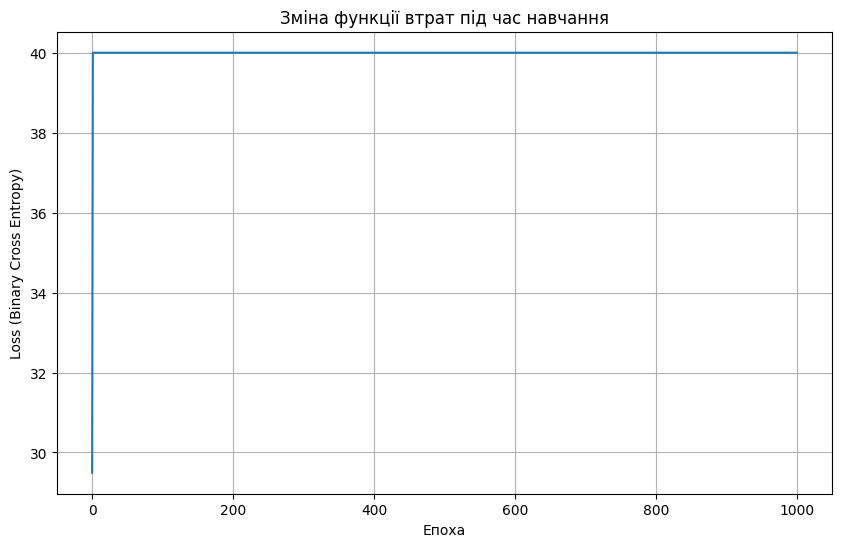


Фінальні результати:

Фінальні передбачення:
tensor([[1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.],
        [1.]])

Справжні мітки:
tensor([[0.],
        [1.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [1.],
        [0.],
        [1.],
        [1.],
        [0.],
        [1.]])

Фінальний loss:
40.0

Аналіз точності:
Точність: 60.00%
Правильні передбачення: 9.0/15

Порівняння передбачень та міток:
Приклад 1: Передбачення=1, Мітка=0 ✗
Приклад 2: Передбачення=1, Мітка=1 ✓
Приклад 3: Передбачення=1, Мітка=1 ✓
Приклад 4: Передбачення=1, Мітка=0 ✗
Приклад 5: Передбачення=1, Мітка=1 ✓
Приклад 6: Передбачення=1, Мітка=0 ✗
Приклад 7: Передбачення=1, Мітка=1 ✓
Приклад 8: Передбачення=1, Мітка=1 ✓
Приклад 9: Передбачення=1, Мітка=0 ✗
Приклад 10: Передбачення=1, Мітка=1 ✓
Приклад 11: Передбачен

In [17]:
import matplotlib.pyplot as plt

def train_model(model, train_loader, optimizer, num_epochs):
    """
    Функція для навчання моделі.

    Args:
        model: модель для навчання
        train_loader: DataLoader з навчальними даними
        optimizer: оптимізатор
        num_epochs: кількість епох

    Returns:
        список значень втрат для кожної епохи
    """
    loss_history = []

    for epoch in range(num_epochs):
        epoch_losses = []

        for batch_idx, (inputs, targets) in enumerate(train_loader):
            # Прямий прохід
            predictions = model(inputs)

            # Обчислення втрат
            loss = F.binary_cross_entropy(predictions, targets)

            # Зворотний прохід
            optimizer.zero_grad()  # Скидання градієнтів
            loss.backward()        # Обчислення градієнтів
            optimizer.step()      # Оновлення ваг

            epoch_losses.append(loss.item())

        # Середні втрати за епоху
        avg_loss = np.mean(epoch_losses)
        loss_history.append(avg_loss)

        # Виведення прогресу кожні 100 епох
        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Average Loss: {avg_loss:.4f}')

    return loss_history

# Навчання моделі
print("Початок навчання моделі...")
print("="*50)
loss_history = train_model(model, train_dl, opt, num_epochs=1000)

# Візуалізація зміни втрат
plt.figure(figsize=(10, 6))
plt.plot(loss_history)
plt.title('Зміна функції втрат під час навчання')
plt.xlabel('Епоха')
plt.ylabel('Loss (Binary Cross Entropy)')
plt.grid(True)
plt.show()

# Фінальні передбачення
print("\n" + "="*50)
print("Фінальні результати:")
print("="*50)

model.eval()  # Переводимо модель в режим оцінки
with torch.no_grad():
    all_predictions = model(inputs_tensor)
    final_loss = F.binary_cross_entropy(all_predictions, targets_tensor)

print("\nФінальні передбачення:")
print(all_predictions)
print("\nСправжні мітки:")
print(targets_tensor)
print("\nФінальний loss:")
print(final_loss.item())

# Аналіз точності
predicted_classes = (all_predictions > 0.5).float()
correct = (predicted_classes == targets_tensor).float()
accuracy = correct.mean().item() * 100

print("\n" + "="*50)
print("Аналіз точності:")
print("="*50)
print(f"Точність: {accuracy:.2f}%")
print(f"Правильні передбачення: {correct.sum().item()}/{len(targets_tensor)}")
print("\nПорівняння передбачень та міток:")
for i in range(len(targets_tensor)):
    pred_class = predicted_classes[i].item()
    true_class = targets_tensor[i].item()
    match = "✓" if pred_class == true_class else "✗"
    print(f"Приклад {i+1}: Передбачення={pred_class:.0f}, Мітка={true_class:.0f} {match}")


---

# **Загальний висновок по всьому документу**

## **Вступ**

У цьому документі ми пройшли повний шлях від реалізації логістичної регресії з нуля до використання високорівневих інструментів PyTorch. Це дослідження охопило дві основні секції, кожна з яких демонструє різні підходи до створення та навчання моделей машинного навчання.

---

## **Основні досягнення та навички**

### **1. Фундаментальне розуміння нейронних мереж**

У першій секції ми реалізували логістичну регресію з нуля, використовуючи лише базові операції PyTorch. Це дозволило нам:

- **Глибоко зрозуміти математичні основи:** Ми безпосередньо працювали з формулами сигмоїдної функції, бінарної крос-ентропії та градієнтного спуску, що забезпечило міцне розуміння того, як працюють нейронні мережі на найнижчому рівні.

- **Зіткнутися з практичними проблемами:** Ми практично побачили проблему зникнення градієнтів (gradient vanishing), яка виникає через насичення сигмоїдної функції активації. Це важливе спостереження, яке допомагає розуміти, чому правильна ініціалізація ваг є критичною для успішного навчання.

- **Опанувати механізми PyTorch:** Ми навчилися працювати з тензорами, автоматичним диференціюванням (autograd), градієнтами та листовими тензорами. Розуміння цих концепцій є фундаментальним для роботи з PyTorch.

### **2. Практичні навички роботи з PyTorch**

У другій секції ми використали високорівневі інструменти PyTorch, що дозволило нам:

- **Створити повний pipeline навчання:** Ми навчилися використовувати `TensorDataset` та `DataLoader` для ефективної роботи з даними, створювати моделі через `nn.Module`, налаштовувати оптимізатори та функції втрат, та реалізовувати повний цикл навчання.

- **Порівняти підходи:** Порівняння реалізації з нуля та з використанням високорівневих API показало, що обидва підходи мають свої переваги: реалізація з нуля дає глибоке розуміння, а високорівневі інструменти спрощують розробку та роблять код більш читабельним.

- **Отримати практичний досвід:** Ми навчилися візуалізувати процес навчання, аналізувати результати та оцінювати якість моделі через метрики точності.

---

## **Ключові висновки та спостереження**

### **1. Важливість правильної ініціалізації**

Одним з найважливіших відкриттів було розуміння критичної ролі правильної ініціалізації ваг. Великі випадкові значення призводять до насичення сигмоїдної функції, що викликає зникнення градієнтів та робить навчання неможливим. Маленькі значення навколо нуля забезпечують ефективне навчання.

### **2. Проблема зникнення градієнтів**

Ми практично побачили, як проблема зникнення градієнтів виникає в реальних умовах. Це важливе спостереження для розуміння проблем навчання глибоких нейронних мереж, де ця проблема стає ще більш критичною через наявність багатьох шарів.

### **3. Баланс між розумінням та практичністю**

Реалізація з нуля дає глибоке розуміння, але може бути складною та схильною до помилок. Використання високорівневих інструментів спрощує розробку, але вимагає розуміння основ, щоб ефективно використовувати ці інструменти та вирішувати проблеми, коли вони виникають.

### **4. Важливість візуалізації та моніторингу**

Візуалізація процесу навчання (графіки зміни втрат) та детальний аналіз результатів дозволяють відстежувати прогрес, виявляти проблеми та оцінювати якість моделі. Це критично важливі навички для практичної роботи з машинним навчанням.

---

## **Практичне застосування отриманих знань**

Отримані знання та навички можуть бути застосовані для:

1. **Розробки нових моделей:** Розуміння основ дозволяє створювати та модифікувати архітектури нейронних мереж під конкретні задачі.

2. **Діагностики проблем:** Знаючи, як працюють механізми "під капотом", можна ефективно діагностувати та вирішувати проблеми під час навчання моделей.

3. **Оптимізації навчання:** Розуміння впливу ініціалізації, вибору оптимізатора та функції втрат дозволяє оптимізувати процес навчання для досягнення кращих результатів.

4. **Розширення на більш складні моделі:** Отримані знання є фундаментом для вивчення більш складних архітектур, таких як багатошарові перцептрони, згорткові нейронні мережі та рекурентні нейронні мережі.

---

## **Висновок**

Цей документ продемонстрував повний цикл роботи з логістичною регресією - від математичних основ до практичної реалізації. Ми навчилися:

- Реалізовувати моделі з нуля, розуміючи кожен крок
- Використовувати високорівневі інструменти PyTorch для ефективної розробки
- Діагностувати та вирішувати практичні проблеми навчання
- Аналізувати та оцінювати результати роботи моделей

Отримані знання та навички є міцним фундаментом для подальшого вивчення та роботи з нейронними мережами та машинним навчанням загалом. Розуміння того, як працюють речі на найнижчому рівні, поєднане з вмінням використовувати потужні інструменти фреймворків, робить нас ефективними та успішними практиками машинного навчання.

---
